# CECS 385 — Quantum vs. Classical Portfolio Selection (20 ETFs)

**Question:** When given the same AI return forecasts and risk estimates, how close does QAOA get to the exact classical optimum when selecting **3 of 20 ETFs**?

- **AI:** Random Forest estimates next-month ETF returns using data available through December 2024.
- **Classical:** Check all **1,140** combinations, plus a greedy baseline.
- **Quantum:** QAOA with 20 qubits, a constraint-preserving XY mixer, and Qiskit Aer.
- **Out-of-sample check:** Compare the chosen portfolios' *actual January 2025 returns* (one month is not enough for Sharpe ratio conclusions).

**Important:** A QAOA simulator is not real quantum hardware. Exhaustive search is guaranteed to match or exceed QAOA on the **same estimated score**. The purpose is to measure QAOA's accuracy and computation cost.

Run in **Google Colab** from top to bottom. The QAOA step can be relatively slow with 20 qubits.

## 1. Install packages

In [36]:
%pip -q install qiskit qiskit-aer yfinance scikit-learn pandas numpy matplotlib scipy


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


## 2. Settings
`QUICK_TEST = True` uses fewer optimization iterations. For a more meaningful experiment, switch it to `False` after the first successful run. Both settings still use **20 ETFs**.

In [37]:
import pandas as pd

url = "https://raw.githubusercontent.com/manisahni/marketdata/main/daily_adjclose.csv"

github_data = pd.read_csv(url)

print("Dataset shape:", github_data.shape)
print("Available columns:")
print(github_data.columns.tolist())

Dataset shape: (5688, 28)
Available columns:
['Date', 'DBC', 'EEM', 'EFA', 'GLD', 'HYG', 'IEF', 'IWM', 'LQD', 'QQQ', 'SHY', 'SPY', 'TIP', 'TLT', 'UUP', 'VNQ', 'XLB', 'XLE', 'XLF', 'XLI', 'XLK', 'XLP', 'XLU', 'XLV', 'XLY', '^IRX', '^VIX', '^VIX3M']


In [38]:
import time
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

from sklearn.ensemble import RandomForestRegressor
from scipy.optimize import minimize
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
url = "https://raw.githubusercontent.com/manisahni/marketdata/main/daily_adjclose.csv"
TICKERS = [
    "XLK", "XLV", "XLF", "XLE", "XLI",
    "XLP", "XLU", "XLB", "XLY", "SPY",
    "IWM", "EFA", "EEM", "TLT", "IEF",
    "GLD", "LQD", "VNQ", "TIP", "HYG"
]
# XLC started in 2018, so training is limited to 2018 onward for a complete 20-ETF sample.
CHOOSE = 3
LAMBDA = 1.0
QUICK_TEST = True
SHOTS = 128 if QUICK_TEST else 1024
MAX_ITER = 12 if QUICK_TEST else 75
DEPTH = 1 if QUICK_TEST else 2
SEED = 7
CIRCUIT_SCALE = 100.0  # magnifies small decimal return scores for quantum phase gates

print("ETFs:", len(TICKERS), " | portfolios:", len(list(itertools.combinations(TICKERS, CHOOSE))))

ETFs: 20  | portfolios: 1140


## 3. Download prices and prepare Random Forest forecasts

Prices are adjusted for splits and distributions. The forecasting features at a given month end use **past months only**. The target is the *next month's* return. Models train only on historical observations whose target is known by December 2024. January 2025 is reserved for checking realized performance.

This uses Yahoo Finance through `yfinance`, not the original GitHub CSV. If downloads fail, rerun the cell or use a saved adjusted-price CSV with the same ticker columns.

In [39]:

# Load real historical ETF prices from GitHub
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor

url = "https://raw.githubusercontent.com/manisahni/marketdata/main/daily_adjclose.csv"

data = pd.read_csv(url, index_col="Date", parse_dates=True)
data = data.sort_index()

# Check that all 20 ETFs are available
missing = [ticker for ticker in TICKERS if ticker not in data.columns]

if missing:
    raise ValueError(f"Missing ETFs in GitHub dataset: {missing}")

# Use the same historical period as the original experiment
prices = data.loc["2017-01-01":"2025-01-31", TICKERS].copy()

# Forward-fill occasional missing trading days, but not missing
# prices before an ETF existed
prices = prices.ffill()

monthly = prices.resample("ME").last()
monthly = monthly.loc["2019-01-31":"2025-01-31"]

if monthly.loc["2020-01-31":"2025-01-31"].isna().any().any():
    raise ValueError("Missing ETF prices in the analysis period")

if (monthly <= 0).any().any():
    raise ValueError("ETF prices must be positive")

# Calculate monthly percentage returns
monthly_returns = monthly.pct_change(fill_method=None)

# Build features for the Random Forest models
features = {}

for ticker in TICKERS:
    r = monthly_returns[ticker]

    features[ticker] = pd.DataFrame({
        "last_month": r,
        "last_3_months": monthly[ticker].pct_change(3),
        "last_6_months": monthly[ticker].pct_change(6),
        "volatility_3m": r.rolling(3).std(),
        "next_month": r.shift(-1)
    }).dropna()

# Predict January 2025 returns
predictions = []

columns = [
    "last_month",
    "last_3_months",
    "last_6_months",
    "volatility_3m"
]

for ticker in TICKERS:
    df = features[ticker]

    # Train only on examples whose targets are known by Dec 2024
    train = df.loc[df.index <= "2024-11-30"]

    r = monthly_returns[ticker]

    forecast_row = pd.DataFrame({
        "last_month": r,
        "last_3_months": monthly[ticker].pct_change(3),
        "last_6_months": monthly[ticker].pct_change(6),
        "volatility_3m": r.rolling(3).std()
    }).loc[[pd.Timestamp("2024-12-31")]]

    if len(train) < 24 or forecast_row.isna().any().any():
        raise ValueError(f"Not enough training data for {ticker}")

    model = RandomForestRegressor(
        n_estimators=100,
        min_samples_leaf=3,
        random_state=SEED
    )

    model.fit(train[columns], train["next_month"])

    predictions.append(float(model.predict(forecast_row[columns])[0]))

# Estimated January 2025 returns
mu = np.array(predictions)

# Estimate portfolio risk using 2022-2024 returns
cov = monthly_returns.loc[
    "2022-01-31":"2024-12-31", TICKERS
].cov().values

# Actual January 2025 returns for historical evaluation
actual_jan = monthly_returns.loc[
    pd.Timestamp("2025-01-31"), TICKERS
].values

# Validate calculated values
assert np.isfinite(mu).all()
assert np.isfinite(cov).all()
assert np.isfinite(actual_jan).all()

print("DATA SOURCE: GitHub - manisahni/marketdata")
print("ETFs:", len(TICKERS))
print("Monthly observations:", len(monthly))
print("Portfolios:", 1140)

print("\nJanuary 2025 ETF predictions:")

display(pd.DataFrame({
    "ETF": TICKERS,
    "Predicted Jan return": mu,
    "Actual Jan return": actual_jan
}).round(4))


DATA SOURCE: GitHub - manisahni/marketdata
ETFs: 20
Monthly observations: 73
Portfolios: 1140

January 2025 ETF predictions:


,ETF,Predicted Jan return,Actual Jan return
0,XLK,0.0355,-0.0074
1,XLV,0.0328,0.0676
2,XLF,0.0463,0.0650
3,XLE,0.0552,0.0231
4,XLI,-0.0081,0.0500
5,XLP,0.0128,0.0047
6,XLU,0.0373,0.0289
7,XLB,-0.0124,0.0553
8,XLY,-0.0007,0.0349
9,SPY,0.0404,0.0269


,monthly_return,rolling_3m,rolling_6m,volatility_6m
Date,,,,
2024-02-29,0.0522,0.0379,0.0227,0.0511
2024-03-31,0.0327,0.0336,0.0360,0.0378
2024-04-30,-0.0403,0.0149,0.0329,0.0438
2024-05-31,0.0506,0.0143,0.0261,0.0353
2024-06-30,0.0353,0.0152,0.0244,0.0344
2024-07-31,0.0121,0.0327,0.0238,0.0346
2024-08-31,0.0234,0.0236,0.0190,0.0317
2024-09-30,0.0210,0.0188,0.0170,0.0311
2024-10-31,-0.0089,0.0118,0.0222,0.0202


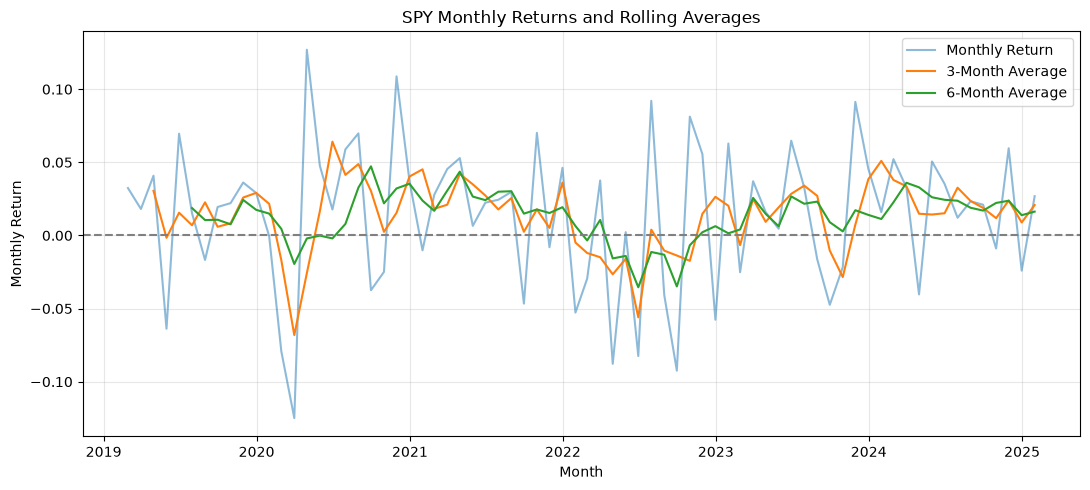

In [40]:
ticker = "SPY"

ts = pd.DataFrame({
    "monthly_return": monthly_returns[ticker]
})
ts["rolling_3m"] = ts["monthly_return"].rolling(3).mean()
ts["rolling_6m"] = ts["monthly_return"].rolling(6).mean()

# Historical volatility
ts["volatility_6m"] = ts["monthly_return"].rolling(6).std()

display(ts.tail(12).round(4))
plt.figure(figsize=(11, 5))

plt.plot(ts.index, ts["monthly_return"],
         label="Monthly Return", alpha=0.5)

plt.plot(ts.index, ts["rolling_3m"],
         label="3-Month Average")

plt.plot(ts.index, ts["rolling_6m"],
         label="6-Month Average")

plt.axhline(0, color="gray", linestyle="--")

plt.title("SPY Monthly Returns and Rolling Averages")
plt.xlabel("Month")
plt.ylabel("Monthly Return")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 4. Same portfolio scoring formula for every optimizer

Equal-weight portfolio with exactly 3 ETFs:

\[	ext{Score}(x)=\mu^T w-\lambda w^T\Sigma w, \qquad w=x/3.\]

This is an **estimated objective score**, not a prediction of guaranteed realized profit. `LAMBDA = 1.0` is a research setting and can be varied later.

In [41]:
def portfolio_score(indices):
    ids = list(indices)
    w = np.zeros(len(TICKERS))
    w[ids] = 1 / CHOOSE
    return float(mu @ w - LAMBDA * (w @ cov @ w))

def portfolio_names(indices):
    return [TICKERS[i] for i in indices]

start = time.perf_counter()
all_portfolios = list(itertools.combinations(range(len(TICKERS)), CHOOSE))
scores = np.array([portfolio_score(p) for p in all_portfolios])
best_i = int(np.argmax(scores))
classical_choice = all_portfolios[best_i]
classical_score = float(scores[best_i])
classical_time = time.perf_counter() - start

# Greedy: add whichever ETF gives the best immediate total score until three are selected.
start = time.perf_counter()
greedy_choice = []
while len(greedy_choice) < CHOOSE:
    candidates = [i for i in range(len(TICKERS)) if i not in greedy_choice]
    greedy_choice.append(max(candidates, key=lambda i: portfolio_score(greedy_choice + [i])))
greedy_choice = tuple(sorted(greedy_choice))
greedy_time = time.perf_counter() - start

print("Classical:", portfolio_names(classical_choice), "score:", round(classical_score, 6))
print("Greedy:   ", portfolio_names(greedy_choice), "score:", round(portfolio_score(greedy_choice), 6))
print("Total combinations:", len(all_portfolios))

Classical: ['XLF', 'XLE', 'SPY'] score: 0.044302
Greedy:    ['XLF', 'XLE', 'SPY'] score: 0.044302
Total combinations: 1140


## 5. QAOA with a three-ETF constraint

The initial bitstring has exactly three selected ETFs. The **XY mixer** moves selections between neighboring qubits while preserving the number of selected ETFs. Consequently, sampled bitstrings should always select three ETFs (apart from numerical/transpilation issues).

`RZ`, `RZZ`, `RXX`, and `RYY` gates encode the portfolio score and enable mixing. This example deliberately uses a simple, student-readable circuit. It isn't a claim of quantum speedup.

**Practical warning:** 20 simulated qubits with many two-qubit gates can take considerable time. Quick mode uses `p=1`, 128 shots and 12 COBYLA iterations as a *smoke test*, not a reliable performance estimate.

In [42]:
# Score = sum(a[i] * x[i]) + sum(b[i,j] * x[i] * x[j]) for equal weights
N = len(TICKERS)
a = mu / CHOOSE - LAMBDA * np.diag(cov) / (CHOOSE ** 2)
b = np.zeros((N, N))
for i in range(N):
    for j in range(i+1, N):
        b[i, j] = -2 * LAMBDA * cov[i, j] / (CHOOSE ** 2)

# Start with three spread-out ETFs, rather than choosing the optimum in advance.
start_bits = [0, 7, 14]
# Verify quantum coefficients match classical scores

def score_from_quantum_coefficients(indices):
    bits = np.zeros(N)
    bits[list(indices)] = 1

    linear = np.dot(a, bits)

    interactions = sum(
        b[i, j] * bits[i] * bits[j]
        for i in range(N)
        for j in range(i + 1, N)
    )

    return float(linear + interactions)


# Check all 1,140 valid portfolios
differences = []

for portfolio in all_portfolios:
    classical = portfolio_score(portfolio)
    quantum_encoded = score_from_quantum_coefficients(portfolio)
    differences.append(abs(classical - quantum_encoded))

print("Portfolios checked:", len(differences))
print("Maximum score difference:", max(differences))

assert np.allclose(differences, 0, atol=1e-10)

print("PASS: Quantum coefficients match classical objective")
# Use alternating nearest-neighbor XY layers on a ring, avoiding expensive generic matrix gates.
def build_circuit(gammas, betas):
    qc = QuantumCircuit(N)
    for i in start_bits:
        qc.x(i)

    for gamma, beta in zip(gammas, betas):
        # exp(+i gamma * score) up to a global phase.
        for i in range(N):
            angle = CIRCUIT_SCALE * gamma * (a[i] + 0.5 * sum(b[min(i,j), max(i,j)] for j in range(N) if j != i))
            qc.rz(angle, i)
        for i in range(N):
            for j in range(i + 1, N):
                if abs(b[i, j]) > 1e-12:
                    qc.rzz(-CIRCUIT_SCALE * gamma * b[i, j] / 2, i, j)

        # Every gate commutes with total excitation number (number of 1s).
        for offset in (0, 1):
            for i in range(offset, N - 1, 2):
                qc.rxx(beta, i, i + 1)
                qc.ryy(beta, i, i + 1)
        qc.rxx(beta, N - 1, 0)
        qc.ryy(beta, N - 1, 0)

    qc.measure_all()
    return qc

simulator = AerSimulator(method="matrix_product_state")

def sample_qaoa(theta, shots=SHOTS):
    gammas = theta[:DEPTH]
    betas = theta[DEPTH:]
    circuit = build_circuit(gammas, betas)
    # Reverse bits: Qiskit strings are displayed highest qubit index first.
    result = simulator.run(transpile(circuit, simulator, optimization_level=1), shots=shots, seed_simulator=SEED).result()
    counts = result.get_counts()
    scored = []
    for bitstring, count in counts.items():
        ids = tuple(i for i, bit in enumerate(bitstring[::-1]) if bit == "1")
        if len(ids) == CHOOSE:
            scored.append((ids, count, portfolio_score(ids)))
    return scored

calls = [0]
def loss(theta):
    result = sample_qaoa(theta)
    calls[0] += 1
    if not result:
        return 1e4
    total = sum(count for _, count, _ in result)
    return -sum(count * score for _, count, score in result) / total

initial = np.r_[np.full(DEPTH, 0.8), np.full(DEPTH, 0.5)]
start = time.perf_counter()
optimization = minimize(loss, initial, method="COBYLA", options={"maxiter": MAX_ITER, "rhobeg": 0.4})
qaoa_time = time.perf_counter() - start

# Evaluate a larger final sample and choose the best feasible portfolio observed.
final_samples = sample_qaoa(optimization.x, shots=max(1024, SHOTS))
if not final_samples:
    raise RuntimeError("QAOA produced no valid 3-ETF portfolios.")
quantum_choice, _, quantum_score = max(final_samples, key=lambda row: row[2])
valid_shots = sum(count for _, count, _ in final_samples)

print("QAOA:     ", portfolio_names(quantum_choice))
print("QAOA score:", round(quantum_score, 6))
print("Exact optimum:", round(classical_score, 6))
print("Absolute gap:", round(classical_score - quantum_score, 6))
print("Found optimum:", np.isclose(quantum_score, classical_score, atol=1e-10))
print("Valid sampled shots:", valid_shots)
print("Optimizer calls:", calls[0])
print("QAOA runtime (seconds):", round(qaoa_time, 2))

Portfolios checked: 1140
Maximum score difference: 1.3877787807814457e-17
PASS: Quantum coefficients match classical objective
QAOA:      ['XLF', 'XLU', 'LQD']
QAOA score: 0.027837
Exact optimum: 0.044302
Absolute gap: 0.016465
Found optimum: False
Valid sampled shots: 1024
Optimizer calls: 12
QAOA runtime (seconds): 0.81


In [43]:
def run_qaoa_trial(seed, depth=1, max_iter=30):

    rng = np.random.default_rng(seed)
    sample_rng = np.random.default_rng(seed + 10000)
    sim = AerSimulator(method="matrix_product_state")

    # Different starting parameters for every run
    starting = rng.uniform(0, 2 * np.pi, depth * 2)

    def sample(theta, shots):

        gammas = theta[:depth]
        betas = theta[depth:]

        qc = build_circuit(gammas, betas)
        qc = transpile(qc, sim, optimization_level=1)

        result = sim.run(
            qc,
            shots=shots,
            seed_simulator=int(sample_rng.integers(0, 2**31 - 1))
        ).result()

        return result.get_counts()

    def loss(theta):

        counts = sample(theta, 128)

        total = 0
        valid = 0

        for bits, count in counts.items():

            selected = tuple(
                i for i, bit in enumerate(bits[::-1])
                if bit == "1"
            )

            if len(selected) == CHOOSE:
                total += portfolio_score(selected) * count
                valid += count

        if valid == 0:
            return 10000

        return -total / valid

    start = time.perf_counter()

    result = minimize(
        loss,
        starting,
        method="COBYLA",
        options={"maxiter": max_iter}
    )

    counts = sample(result.x, 1024)

    best_score = -np.inf
    best_portfolio = None
    valid_shots = 0

    for bits, count in counts.items():

        selected = tuple(
            i for i, bit in enumerate(bits[::-1])
            if bit == "1"
        )

        if len(selected) == CHOOSE:

            valid_shots += count
            s = portfolio_score(selected)

            if s > best_score:
                best_score = s
                best_portfolio = selected

    seconds = time.perf_counter() - start

    if best_portfolio is None:
        best_score = np.nan

    return {
        "seed": seed,
        "depth": depth,
        "score": best_score,
        "gap": classical_score - best_score,
        "found_optimum": (
            best_portfolio is not None
            and np.isclose(best_score, classical_score, atol=1e-8)
        ),
        "runtime": seconds,
        "valid_shots": valid_shots,
        "optimizer_calls": result.nfev,
        "portfolio": (
            ", ".join(portfolio_names(best_portfolio))
            if best_portfolio is not None else "None"
        )
    }

In [44]:
baseline_predictions = []

for _, row in forecast_df.iterrows():
    previous_return = monthly_returns.loc[
        row["decision_month"], row["ETF"]
    ]
    baseline_predictions.append(previous_return)

forecast_df["baseline_prediction"] = baseline_predictions

rf_mae = mean_absolute_error(
    forecast_df["actual"],
    forecast_df["predicted"]
)

baseline_mae = mean_absolute_error(
    forecast_df["actual"],
    forecast_df["baseline_prediction"]
)

print("Random Forest MAE:", round(rf_mae, 5))
print("Simple baseline MAE:", round(baseline_mae, 5))

Random Forest MAE: 0.03757
Simple baseline MAE: 0.04881


## 6. Compare the methods and check actual January 2025 returns

**Note:** One month of realized return is only an illustration, not proof that an algorithm will produce better investment results. The estimated optimization score is the proper primary comparison for this one-period study.

         Method          ETFs    Score  Seconds  Jan 2025 return  Gap from exact
Classical exact XLF, XLE, SPY 0.044302 0.026965         0.038314        0.000000
         Greedy XLF, XLE, SPY 0.044302 0.000969         0.038314        0.000000
   Quantum QAOA XLF, XLU, LQD 0.027837 0.808385         0.033236        0.016465


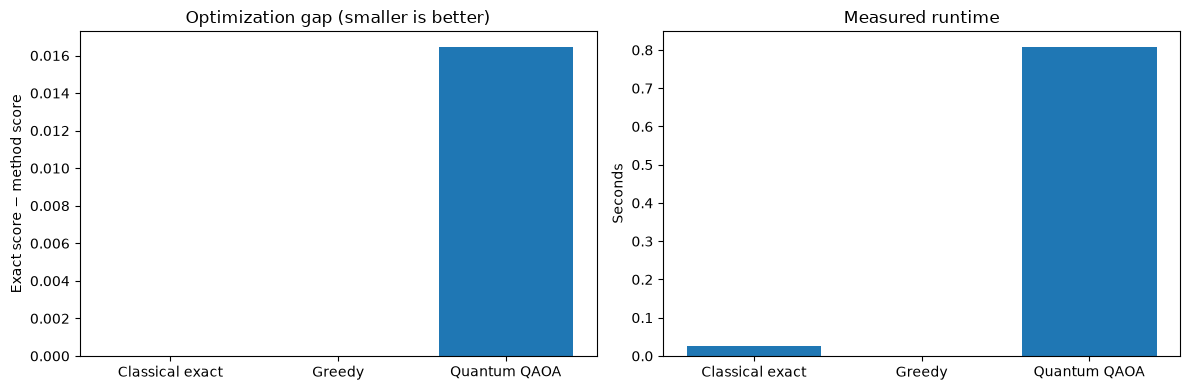

In [45]:
def jan_return(indices):
    return float(np.mean(actual_jan[list(indices)]))

results = pd.DataFrame([
    {"Method": "Classical exact", "ETFs": ", ".join(portfolio_names(classical_choice)), "Score": classical_score, "Seconds": classical_time, "Jan 2025 return": jan_return(classical_choice)},
    {"Method": "Greedy", "ETFs": ", ".join(portfolio_names(greedy_choice)), "Score": portfolio_score(greedy_choice), "Seconds": greedy_time, "Jan 2025 return": jan_return(greedy_choice)},
    {"Method": "Quantum QAOA", "ETFs": ", ".join(portfolio_names(quantum_choice)), "Score": quantum_score, "Seconds": qaoa_time, "Jan 2025 return": jan_return(quantum_choice)},
])
results["Gap from exact"] = classical_score - results["Score"]
print(results.round(6).to_string(index=False))
results.to_csv("quantum_vs_classical_20_etfs.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(results["Method"], results["Gap from exact"])
axes[0].set_title("Optimization gap (smaller is better)")
axes[0].set_ylabel("Exact score − method score")
axes[1].bar(results["Method"], results["Seconds"])
axes[1].set_title("Measured runtime")
axes[1].set_ylabel("Seconds")
plt.tight_layout()
plt.show()

In [46]:
print("CLASSICAL RESULTS")
print("-------------------")
print("Best Portfolio:", classical_choice)
print("Best Score:", round(classical_score, 6))
print("Runtime:", round(classical_time, 5), "seconds")

print("\nGREEDY RESULTS")
print("-------------------")
print("Portfolio:", greedy_choice)
print("Score:", round(portfolio_score(greedy_choice), 6))
print("Runtime:", round(greedy_time, 5), "seconds")

CLASSICAL RESULTS
-------------------
Best Portfolio: (2, 3, 9)
Best Score: 0.044302
Runtime: 0.02697 seconds

GREEDY RESULTS
-------------------
Portfolio: (2, 3, 9)
Score: 0.044302
Runtime: 0.00097 seconds


In [47]:
# First test with 3 seeds

DEPTH = 1

results = []

for seed in [1, 11]:

    run = run_qaoa_trial(
        seed=seed,
        depth=DEPTH,
        max_iter=30
    )

    results.append(run)

    print("Finished seed:", seed)

qaoa_results = pd.DataFrame(results)

display(qaoa_results)

Finished seed: 1
Finished seed: 11


,seed,depth,score,gap,found_optimum,runtime,valid_shots,optimizer_calls,portfolio
0,1,1,0.019935,0.024367,False,2.319004,1024,29,"XLF, XLP, LQD"
1,11,1,0.027837,0.016465,False,2.353693,1024,30,"XLF, XLU, LQD"


In [48]:
all_results = []

for depth in [1, 2]:

    DEPTH = depth

    for seed in range(1, 11):

        run = run_qaoa_trial(
            seed=seed,
            depth=depth,
            max_iter=50
        )

        all_results.append(run)

        print("Depth:", depth, "Seed:", seed, "Done")

comparison = pd.DataFrame(all_results)

display(comparison)

Depth: 1 Seed: 1 Done
Depth: 1 Seed: 2 Done
Depth: 1 Seed: 3 Done
Depth: 1 Seed: 4 Done
Depth: 1 Seed: 5 Done
Depth: 1 Seed: 6 Done
Depth: 1 Seed: 7 Done
Depth: 1 Seed: 8 Done
Depth: 1 Seed: 9 Done
Depth: 1 Seed: 10 Done
Depth: 2 Seed: 1 Done
Depth: 2 Seed: 2 Done
Depth: 2 Seed: 3 Done
Depth: 2 Seed: 4 Done
Depth: 2 Seed: 5 Done
Depth: 2 Seed: 6 Done
Depth: 2 Seed: 7 Done
Depth: 2 Seed: 8 Done
Depth: 2 Seed: 9 Done
Depth: 2 Seed: 10 Done


,seed,depth,score,gap,found_optimum,runtime,valid_shots,optimizer_calls,portfolio
0,1,1,0.019935,0.024367,False,2.107566,1024,29,"XLF, XLP, LQD"
1,2,1,0.027837,0.016465,False,2.334559,1024,30,"XLF, XLU, LQD"
2,3,1,0.019935,0.024367,False,2.036066,1024,28,"XLF, XLP, LQD"
3,4,1,0.028599,0.015703,False,2.374357,1024,30,"XLF, XLU, IEF"
4,5,1,0.027837,0.016465,False,2.382869,1024,31,"XLF, XLU, LQD"
5,6,1,0.027837,0.016465,False,2.355667,1024,32,"XLF, XLU, LQD"
6,7,1,0.019935,0.024367,False,2.357517,1024,30,"XLF, XLP, LQD"
7,8,1,0.019935,0.024367,False,2.640312,1024,35,"XLF, XLP, LQD"
8,9,1,0.019935,0.024367,False,2.292496,1024,29,"XLF, XLP, LQD"
9,10,1,0.019935,0.024367,False,1.106560,1024,16,"XLF, XLP, LQD"


In [49]:
# Normalize gaps using the range of all feasible portfolio scores
score_range = scores.max() - scores.min()

comparison["normalized_gap"] = (
    comparison["gap"] / score_range
)

# Within 5% of the total feasible objective-score range
comparison["near_optimal"] = (
    comparison["normalized_gap"] <= 0.05
)

near_summary = comparison.groupby("depth").agg(
    avg_normalized_gap=("normalized_gap", "mean"),
    near_optimal_rate=("near_optimal", "mean")
)

near_summary["near_optimal_rate"] *= 100

display(near_summary.round(4))

,avg_normalized_gap,near_optimal_rate
depth,,
1,0.3383,0.0
2,0.2269,0.0


In [50]:
summary = comparison.groupby("depth").agg(
    average_score=("score", "mean"),
    average_gap=("gap", "mean"),
    optimal_rate=("found_optimum", "mean"),
    average_runtime=("runtime", "mean"),
    average_valid_shots=("valid_shots", "mean")
)

summary["optimal_rate"] = summary["optimal_rate"] * 100

print("QAOA Experiment Summary")
display(summary.round(4))

print("Classical optimal score:", round(classical_score, 6))
print("Classical runtime:", round(classical_time, 6))
print("Greedy runtime:", round(greedy_time, 6))

QAOA Experiment Summary


,average_score,average_gap,optimal_rate,average_runtime,average_valid_shots
depth,,,,,
1,0.0232,0.0211,0.0,2.1988,1024.0
2,0.0301,0.0142,0.0,4.7820,1024.0


Classical optimal score: 0.044302
Classical runtime: 0.026965
Greedy runtime: 0.000969


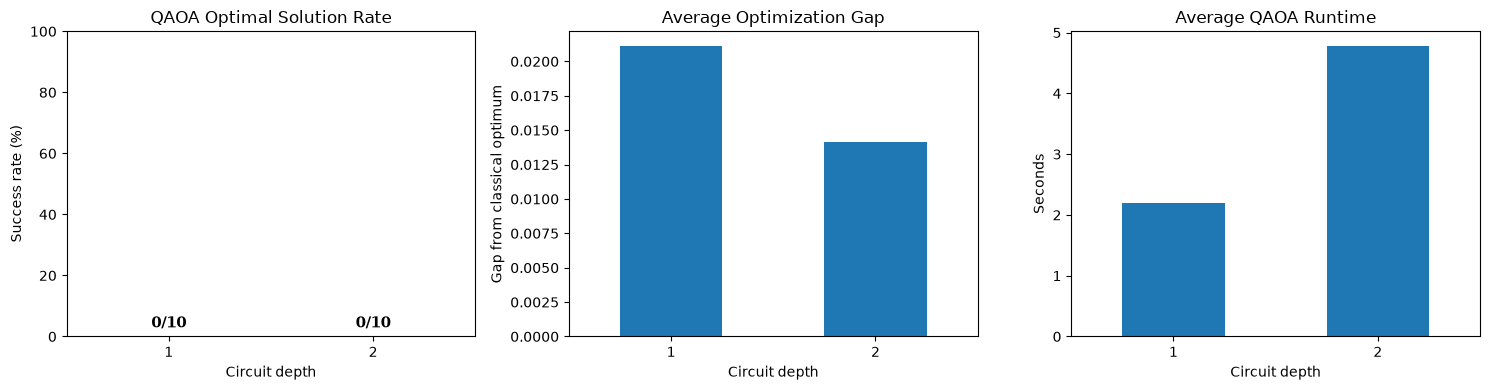

In [51]:
import matplotlib.pyplot as plt
from pathlib import Path

Path("results").mkdir(exist_ok=True)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Graph 1: QAOA optimal solution rate
summary["optimal_rate"].plot(
    kind="bar",
    ax=axes[0],
    title="QAOA Optimal Solution Rate"
)

axes[0].set_ylabel("Success rate (%)")
axes[0].set_ylim(0, 100)

# Show the actual number of successful trials
for i, depth in enumerate(summary.index):
    successes = int(comparison[comparison["depth"] == depth]["found_optimum"].sum())
    trials = len(comparison[comparison["depth"] == depth])
    axes[0].text(i, 3, f"{successes}/{trials}",
                 ha="center", fontsize=11, fontweight="bold")

# Graph 2: Average optimization gap
summary["average_gap"].plot(
    kind="bar",
    ax=axes[1],
    title="Average Optimization Gap"
)
axes[1].set_ylabel("Gap from classical optimum")

# Graph 3: Average runtime
summary["average_runtime"].plot(
    kind="bar",
    ax=axes[2],
    title="Average QAOA Runtime"
)
axes[2].set_ylabel("Seconds")

for ax in axes:
    ax.set_xlabel("Circuit depth")
    ax.tick_params(axis="x", rotation=0)

plt.tight_layout()

# Save BEFORE displaying
fig.savefig(
    "results/qaoa_experiment_results.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [52]:
decision_date = pd.Timestamp("2024-12-31")
train_dates = features["SPY"].loc[
    features["SPY"].index < decision_date
].index

target_dates = train_dates + pd.offsets.MonthEnd(1)

print("Decision date:", decision_date.date())
print("Last training feature date:", train_dates.max().date())
print("Last training target date:", target_dates.max().date())

assert (target_dates <= decision_date).all()

print("PASS: Training targets do not extend beyond the decision date.")

Decision date: 2024-12-31
Last training feature date: 2024-11-30
Last training target date: 2024-12-31
PASS: Training targets do not extend beyond the decision date.


In [53]:

# Walk-forward forecasting experiment
forecast_results = []

decision_dates = pd.date_range(
    "2024-06-30",
    "2024-11-30",
    freq="ME"
)

feature_cols = [
    "last_month",
    "last_3_months",
    "last_6_months",
    "volatility_3m"
]

for decision_date in decision_dates:

    next_month = decision_date + pd.offsets.MonthEnd(1)

    for ticker in TICKERS:

        r = monthly_returns[ticker]

        X_all = pd.DataFrame({
            "last_month": r,
            "last_3_months": monthly[ticker].pct_change(3),
            "last_6_months": monthly[ticker].pct_change(6),
            "volatility_3m": r.rolling(3).std()
        })


        dataset = X_all.copy()
        dataset["target"] = r.shift(-1)
        train = dataset.loc[
            dataset.index < decision_date
        ].dropna()

        current = X_all.loc[[decision_date]]

        if len(train) < 24 or current.isna().any().any():
            raise ValueError(
                f"Insufficient history for {ticker} at {decision_date}"
            )

        model = RandomForestRegressor(
            n_estimators=100,
            min_samples_leaf=3,
            random_state=SEED
        )

        model.fit(train[feature_cols], train["target"])

        prediction = float(model.predict(current)[0])
        actual = float(monthly_returns.loc[next_month, ticker])

        forecast_results.append({
            "decision_month": decision_date,
            "test_month": next_month,
            "ETF": ticker,
            "predicted": prediction,
            "actual": actual,
            "error": prediction - actual
        })

forecast_df = pd.DataFrame(forecast_results)

display(forecast_df.head(10).round(4))

print("Predictions:", len(forecast_df))
print("Months tested:", forecast_df["test_month"].nunique())
print("ETFs tested:", forecast_df["ETF"].nunique())


,decision_month,test_month,ETF,predicted,actual,error
0,2024-06-30,2024-07-31,XLK,0.0438,-0.0328,0.0766
1,2024-06-30,2024-07-31,XLV,0.0075,0.0266,-0.0191
2,2024-06-30,2024-07-31,XLF,-0.0019,0.0640,-0.0659
3,2024-06-30,2024-07-31,XLE,0.0025,0.0226,-0.0201
4,2024-06-30,2024-07-31,XLI,-0.0179,0.0492,-0.0670
5,2024-06-30,2024-07-31,XLP,-0.0117,0.0166,-0.0283
6,2024-06-30,2024-07-31,XLU,0.0156,0.0682,-0.0527
7,2024-06-30,2024-07-31,XLB,-0.0191,0.0434,-0.0624
8,2024-06-30,2024-07-31,XLY,0.0124,0.0279,-0.0155
9,2024-06-30,2024-07-31,SPY,0.0243,0.0121,0.0122


Predictions: 120
Months tested: 6
ETFs tested: 20


In [54]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

mae = mean_absolute_error(
    forecast_df["actual"],
    forecast_df["predicted"]
)

rmse = np.sqrt(mean_squared_error(
    forecast_df["actual"],
    forecast_df["predicted"]
))

direction_accuracy = (
    np.sign(forecast_df["predicted"]) ==
    np.sign(forecast_df["actual"])
).mean() * 100

print("Random Forest Forecasting Results")
print("---------------------------------")
print(f"MAE: {mae:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"Correct return direction: {direction_accuracy:.1f}%")

Random Forest Forecasting Results
---------------------------------
MAE: 0.0376
RMSE: 0.0486
Correct return direction: 50.8%


In [55]:
from pathlib import Path

Path("results").mkdir(exist_ok=True)

forecast_df.to_csv(
    "results/walk_forward_forecasts.csv",
    index=False
)

print("Forecasting results saved.")

Forecasting results saved.


## 7. How to describe the results

- **Exact classical optimization** checks all 1,140 combinations and is the reference answer for the fixed score function.
- **Greedy** is a fast heuristic and may return a lower score.
- **QAOA** is a randomized quantum-circuit simulation. Record whether it matched the optimum, its absolute score gap, feasible samples, and runtime.
- For research on **optimal solution rate**, rerun the QAOA experiment across different seeds and multiple decision dates. One run cannot estimate a success probability.
- For a **Sharpe ratio comparison**, extend to a multi-month walk-forward backtest and run a paired block bootstrap on the matched monthly strategy returns. Do not report a Sharpe-significance test from one month.
- Compare computational time carefully: classical exhaustive-search Python runtime is **not** directly comparable to physical quantum-hardware speed. This only measures the costs of the implementations tested here.

### Settings to report

20 ETFs; choose 3 equally weighted; 1,140 portfolios; expected monthly returns from Random Forest; monthly covariance from 2022–2024; risk aversion `LAMBDA=1.0`; XY constraint-preserving mixer; QAOA `DEPTH`, `SHOTS`, `MAX_ITER`, random seed; final portfolio is highest-scoring valid sampled bitstring; adjusted ETF price source: Yahoo Finance via yfinance.

### Related research

For your literature review, investigate Brandhofer et al., *Benchmarking the Performance of Portfolio Optimization with QAOA* (2023), and the IBM Qiskit Aer guides. This notebook is a simplified implementation, not a direct replication of those papers.

In [56]:
from pathlib import Path

Path("results").mkdir(exist_ok=True)

forecast_df.to_csv(
    "results/walk_forward_forecasts.csv",
    index=False
)

print("Forecasting results saved.")

Forecasting results saved.
